<a href="https://colab.research.google.com/github/MuhammadAmirFarhan/data-science-toolkit./blob/main/Tutorial3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [5]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [6]:
import pandas as pd

df = pd.read_csv('/content/drive/MyDrive/share-of-population-in-extreme-poverty.csv')

df.head()

,Entity,Code,Year,Share of population in poverty ($3 a day),Population,World region according to OWID
0,Afghanistan,AFG,-10000,NaN,14737.0,Asia
1,Afghanistan,AFG,-9000,NaN,20405.0,Asia
2,Afghanistan,AFG,-8000,NaN,28253.0,Asia
3,Afghanistan,AFG,-7000,NaN,39120.0,Asia
4,Afghanistan,AFG,-6000,NaN,54166.0,Asia


In [9]:
df[df["Year"] >= 2010].head(10)

,Entity,Code,Year,Share of population in poverty ($3 a day),Population,World region according to OWID
247,Afghanistan,AFG,2010,NaN,28284088.0,Asia
248,Afghanistan,AFG,2011,NaN,29347708.0,Asia
249,Afghanistan,AFG,2012,NaN,30560036.0,Asia
250,Afghanistan,AFG,2013,NaN,31622709.0,Asia
251,Afghanistan,AFG,2014,NaN,32792528.0,Asia
252,Afghanistan,AFG,2015,NaN,33831767.0,Asia
253,Afghanistan,AFG,2016,NaN,34700613.0,Asia
254,Afghanistan,AFG,2017,NaN,35688941.0,Asia
255,Afghanistan,AFG,2018,NaN,36743040.0,Asia
256,Afghanistan,AFG,2019,NaN,37856125.0,Asia


In [26]:
df.dropna().head(10)

,Entity,Code,Year,Share of population in poverty ($3 a day),Population,World region according to OWID
832,Albania,ALB,1996,2.967841,3245680.0,Europe
838,Albania,ALB,2002,4.194722,3134095.0,Europe
841,Albania,ALB,2005,2.650218,3076156.0,Europe
844,Albania,ALB,2008,0.827308,2992933.0,Europe
848,Albania,ALB,2012,1.794590,2910003.0,Europe
850,Albania,ALB,2014,3.676140,2903748.0,Europe
851,Albania,ALB,2015,1.114864,2898634.0,Europe
852,Albania,ALB,2016,1.140620,2897868.0,Europe
853,Albania,ALB,2017,1.444444,2898245.0,Europe
854,Albania,ALB,2018,1.010029,2894229.0,Europe


In [47]:
print("Table of missing data:\n ")
print(df.isna().sum())

print("\nTable of non-missing data:\n ")
print(df.notna().sum())

Table of missing data:
 
Entity                                           0
Code                                           452
Year                                             0
Share of population in poverty ($3 a day)    56535
Population                                     548
World region according to OWID                4396
dtype: int64

Table of non-missing data:
 
Entity                                       59372
Code                                         58920
Year                                         59372
Share of population in poverty ($3 a day)     2837
Population                                   58824
World region according to OWID               54976
dtype: int64


In [45]:
# Question 2: Is the dataset good?

print("Rows and columns:", df.shape)

print("Repeated country-year records:",
      df.duplicated(subset=["Entity", "Year"]).sum())

# Rename to shorten code
poverty_col = "Share of population in poverty ($3 a day)"

print("Available poverty measurements:",
      df[poverty_col].notna().sum())

# df.loc(rows, columns)
print("Countries/regions with poverty measurements:",
      df.loc[df[poverty_col].notna(), "Entity"].nunique())

# Yes the dataset is good as it is suitable for basic analysis.
# Although, there are many poverty measurements that are missing.
# Therefore, the dataset has some limitations.

Rows and columns: (59372, 6)
Repeated country-year records: 0
Available poverty measurements: 2837
Countries/regions with poverty measurements: 195


In [12]:
# Question 3: How many features are there? Is it enough?

print ( "All columns: ")
print (df.columns.tolist())
print ("Number of columns: ", len(df.columns))
print ("Possible input columns ( Excluding Target ): ", len(df.columns) -1)


# There are 6 columns and 5 possible input features.
# These are enough for basic comparisons, but not enough to accurately predict poverty.

All columns: 
['Entity', 'Code', 'Year', 'Share of population in poverty ($3 a day)', 'Population', 'World region according to OWID']
Number of columns:  6
Possible input columns ( Excluding Target ):  5


In [46]:
# Question 4: How many observations are there? Is it enough?

print("Total observations:", len(df))

print("Observations with poverty data:", df[poverty_col].notna().sum())


# There are 59,372 observations, but only 2,837 contain poverty measurements.
# This is enough for basic exploratory analysis, although the missing data may limit accuracy.

Total observations: 59372
Observations with poverty data: 2837


In [49]:
# Question 5: What datatypes are in the dataset?
# Population is float64 instead of int64 due to it containing misisng values (NaN)
print(df.dtypes)

Entity                                        object
Code                                          object
Year                                           int64
Share of population in poverty ($3 a day)    float64
Population                                   float64
World region according to OWID                object
dtype: object


In [71]:
# Question 6: How many columns have null values? If yes, which column, which rows?

print("Table of missing data:\n ")
print(df.isna().sum())

columns_missing = df.isnull().sum()
print("\nNumber of columns with at least one missing value:", (columns_missing>0).sum())

# axis=1 means the rows are checked horizontally one by one
# axis=0 means going down the columns
rows_missing = df[df.isnull().any(axis=1)]
print("\nNumber of rows with at least one missing value:", len(rows_missing))

print("\nFirst 10 rows containing missing values: \n")
display(rows_missing.head(10))

Table of missing data:
 
Entity                                           0
Code                                           452
Year                                             0
Share of population in poverty ($3 a day)    56535
Population                                     548
World region according to OWID                4396
dtype: int64

Number of columns with at least one missing value: 4

Number of rows with at least one missing value: 57117

First 10 rows containing missing values: 



,Entity,Code,Year,Share of population in poverty ($3 a day),Population,World region according to OWID
0,Afghanistan,AFG,-10000,NaN,14737.0,Asia
1,Afghanistan,AFG,-9000,NaN,20405.0,Asia
2,Afghanistan,AFG,-8000,NaN,28253.0,Asia
3,Afghanistan,AFG,-7000,NaN,39120.0,Asia
4,Afghanistan,AFG,-6000,NaN,54166.0,Asia
5,Afghanistan,AFG,-5000,NaN,75000.0,Asia
6,Afghanistan,AFG,-4000,NaN,306250.0,Asia
7,Afghanistan,AFG,-3000,NaN,537500.0,Asia
8,Afghanistan,AFG,-2000,NaN,768750.0,Asia
9,Afghanistan,AFG,-1000,NaN,1000000.0,Asia


In [80]:
# Question 7: Which column is the feature, which is the target output?

target = poverty_col
features = df.drop(columns=[poverty_col]).columns.tolist()

print("Target is", target)
print("\nFeatures are", features)

Target is Share of population in poverty ($3 a day)

Features are ['Entity', 'Code', 'Year', 'Population', 'World region according to OWID']


In [82]:
# Question 8: Does it have missing values? If yes, which column, which row?

print("Missing values in each column:")
print(df.isnull().sum())

print("\nFirst 10 rows with missing values:")
rows_missing = df[df.isna().any(axis=1)]
display(rows_missing.head(10))

Missing values in each column:
Entity                                           0
Code                                           452
Year                                             0
Share of population in poverty ($3 a day)    56535
Population                                     548
World region according to OWID                4396
dtype: int64

First 10 rows with missing values:


,Entity,Code,Year,Share of population in poverty ($3 a day),Population,World region according to OWID
0,Afghanistan,AFG,-10000,NaN,14737.0,Asia
1,Afghanistan,AFG,-9000,NaN,20405.0,Asia
2,Afghanistan,AFG,-8000,NaN,28253.0,Asia
3,Afghanistan,AFG,-7000,NaN,39120.0,Asia
4,Afghanistan,AFG,-6000,NaN,54166.0,Asia
5,Afghanistan,AFG,-5000,NaN,75000.0,Asia
6,Afghanistan,AFG,-4000,NaN,306250.0,Asia
7,Afghanistan,AFG,-3000,NaN,537500.0,Asia
8,Afghanistan,AFG,-2000,NaN,768750.0,Asia
9,Afghanistan,AFG,-1000,NaN,1000000.0,Asia


Average recorded poverty rate by region:
World region according to OWID
Africa           45.7
Asia             14.8
Europe            1.4
North America     9.2
Oceania          10.7
South America    11.4
Name: Share of population in poverty ($3 a day), dtype: float64


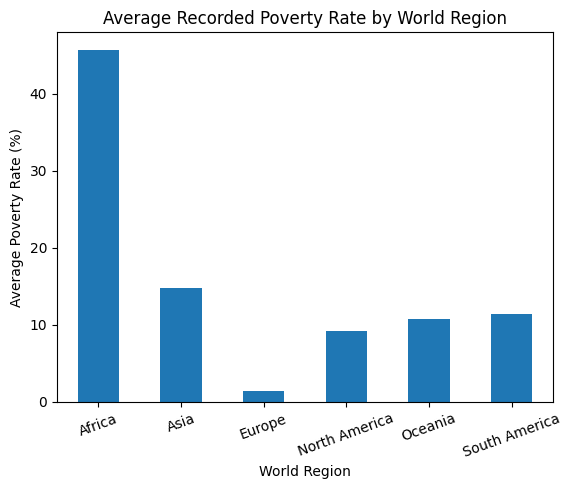

In [92]:
# Question 9: What kind of question can be asked, should we ask. Does the dataset suits the question we are asking?

region = "World region according to OWID"

poverty_rate = df.groupby(region)[poverty_col].mean()

print("Average recorded poverty rate by region:")
print(poverty_rate.round(1))

import matplotlib.pyplot as plt

poverty_rate.plot(kind="bar")

plt.title("Average Recorded Poverty Rate by World Region")
plt.xlabel("World Region")
plt.ylabel("Average Poverty Rate (%)")
plt.xticks(rotation=20)

plt.show()



# Question to be asked:
# How do average recorded poverty rates differ across world regions?

# The dataset is suitable because it contains world regions and poverty percentages.
# However, missing values may affect comparisons.